# Breast Cancer Diagnosis: Comparing ML Classifiers
Predicting whether a breast tumour is **malignant or benign** from 30 measurements of cell nuclei, comparing four models and tuning for the outcome that matters most clinically: **not missing cancer**.

**Data:** the Wisconsin Diagnostic Breast Cancer dataset (569 patients, 30 features), included with scikit-learn.

> Educational project only. Not a medical tool.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (classification_report, roc_auc_score, RocCurveDisplay,
                             ConfusionMatrixDisplay, confusion_matrix, recall_score, precision_score)

plt.rcParams["figure.figsize"] = (8, 4.5)

## 1. Load and explore

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()
df["diagnosis"] = np.where(df.target == 0, "malignant", "benign")
y = (df.target == 0).astype(int)                 # 1 = malignant (the class we must not miss)
X = df[data.feature_names]
print(df.shape); print(df.diagnosis.value_counts().to_string())

(569, 32)
diagnosis
benign       357
malignant    212


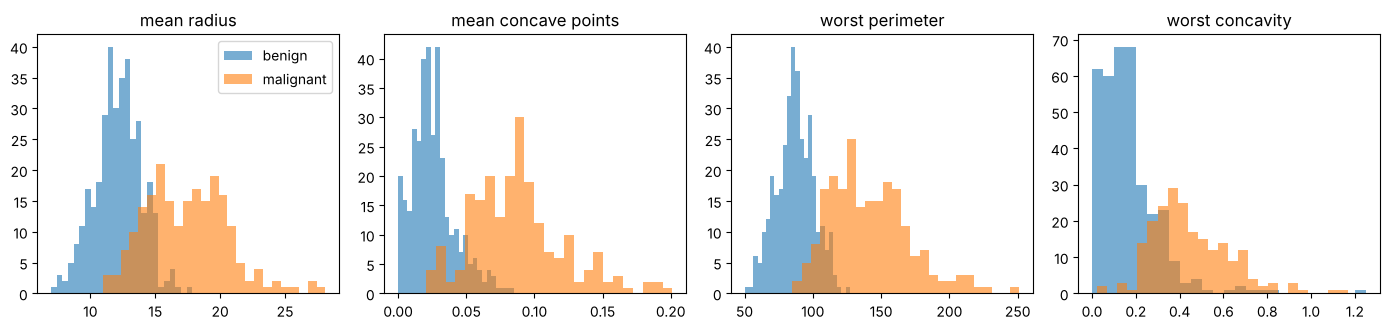

In [3]:
top = ["mean radius", "mean concave points", "worst perimeter", "worst concavity"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, col in zip(axes, top):
    for label, g in df.groupby("diagnosis"):
        ax.hist(g[col], bins=25, alpha=.6, label=label)
    ax.set_title(col)
axes[0].legend(); plt.tight_layout(); plt.show()

## 2. Compare models with 5-fold cross-validation

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "SVM (RBF)": make_pipeline(StandardScaler(), CalibratedClassifierCV(SVC(random_state=42), ensemble=False)),
    "Random forest": RandomForestClassifier(n_estimators=300, random_state=42),
    "k-nearest neighbours": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows = []
for name, m in models.items():
    rows.append({"Model": name,
                 "CV ROC-AUC": cross_val_score(m, X_train, y_train, cv=cv, scoring="roc_auc").mean(),
                 "CV recall (malignant)": cross_val_score(m, X_train, y_train, cv=cv, scoring="recall").mean()})
cv_table = pd.DataFrame(rows).set_index("Model").round(3).sort_values("CV ROC-AUC", ascending=False)
cv_table

,CV ROC-AUC,CV recall (malignant)
Model,,
SVM (RBF),0.994,0.962
Logistic regression,0.991,0.944
Random forest,0.988,0.937
k-nearest neighbours,0.986,0.900


## 3. Test-set performance

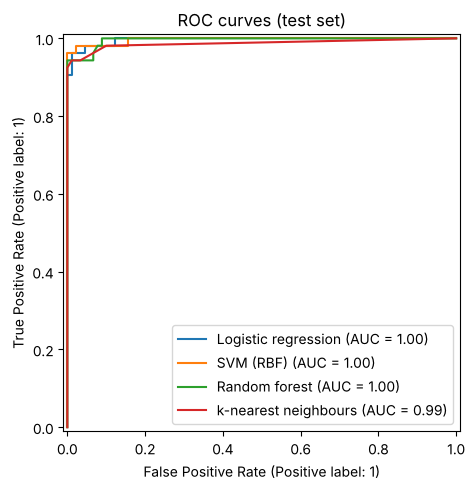

,ROC-AUC,Recall,Precision
Model,,,
Logistic regression,0.996,0.925,0.98
SVM (RBF),0.997,0.962,1.00
Random forest,0.996,0.906,1.00
k-nearest neighbours,0.987,0.925,1.00


In [5]:
fig, ax = plt.subplots(figsize=(6, 5))
test_rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict_proba(X_test)[:, 1]
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=ax)
    pred = (p >= .5).astype(int)
    test_rows.append({"Model": name, "ROC-AUC": roc_auc_score(y_test, p),
                      "Recall": recall_score(y_test, pred), "Precision": precision_score(y_test, pred)})
ax.set_title("ROC curves (test set)"); plt.tight_layout(); plt.show()
pd.DataFrame(test_rows).set_index("Model").round(3)

## 4. Tune the threshold for patient safety
Missing a malignant tumour (false negative) is far worse than a false alarm that leads to a follow-up test. So we lower the decision threshold for the best model until recall on malignant cases is at least **98%**, then check what that costs in precision.

Best model: SVM (RBF) | threshold 0.35

              precision    recall  f1-score   support

      benign      0.989     0.978     0.983        90
   malignant      0.963     0.981     0.972        53

    accuracy                          0.979       143
   macro avg      0.976     0.979     0.978       143
weighted avg      0.979     0.979     0.979       143



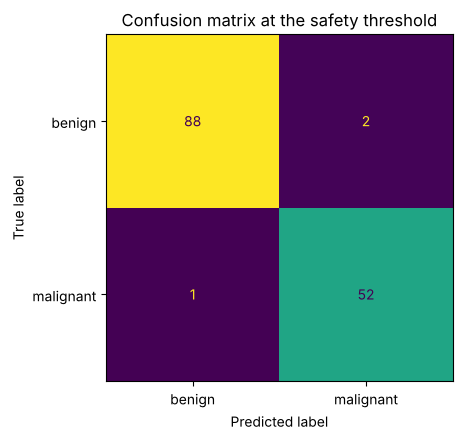

In [6]:
best_name = cv_table.index[0]
best = models[best_name]
proba = best.predict_proba(X_test)[:, 1]
for t in np.arange(0.5, 0.04, -0.05):
    if recall_score(y_test, proba >= t) >= 0.98:
        break
pred = (proba >= t).astype(int)
print(f"Best model: {best_name} | threshold {t:.2f}\n")
print(classification_report(y_test, pred, target_names=["benign", "malignant"], digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["benign", "malignant"]).plot(colorbar=False)
plt.title("Confusion matrix at the safety threshold"); plt.tight_layout(); plt.show()

## 5. Which measurements matter?

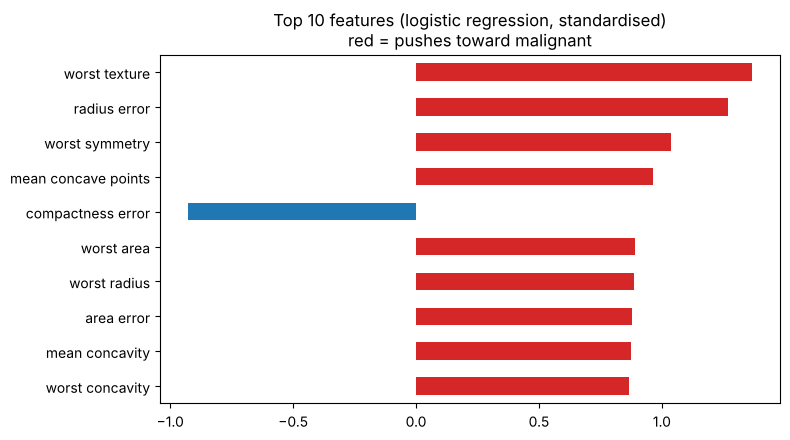

In [7]:
lr = models["Logistic regression"]
coef = pd.Series(lr[-1].coef_[0], index=X.columns).sort_values(key=abs).tail(10)
coef.plot.barh(color=np.where(coef > 0, "tab:red", "tab:blue"),
               title="Top 10 features (logistic regression, standardised)\nred = pushes toward malignant")
plt.tight_layout(); plt.show()

## 6. Conclusions
- All four models separate malignant from benign well. The scaled models (SVM and logistic regression) do best, and the simpler logistic regression stays very close while being easier to explain.
- **Lowering the threshold** trades a few extra false alarms for catching nearly every malignant case, which is the right trade-off for screening.
- Tumour **size and shape irregularity** (worst radius, perimeter, concave points) carry the most signal.

**Next steps:** calibrate probabilities, test on an external dataset, and add per-patient explanations with SHAP.